# Growth Sequential — Neural Net

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import math
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx
from nlls_gram import LevenbergMarquardt

Structural parameters: the same
Aruoba–Fernández-Villaverde–Rubio-Ramírez calibration as the kernel
notebook, with the continuous discount rate mapped from the quarterly
anchor $e^{-\hat\rho/4} = \beta$. The dict `p` is the solver’s
differentiable-parameter pytree —
[`nlls-gram`](https://pypi.org/project/nlls-gram/) differentiates the
solve implicitly with respect to every leaf, the initial condition $k_0$
included.

In [2]:
a = 1.0 / 3.0  # capital share in f(k) = k^a
delta = 0.1  # depreciation rate
rho_hat = -4.0 * math.log(0.9896)  # continuous discount rate (quarterly beta anchor)
sigma_crra = 2.0  # CRRA curvature
k_0 = 1.0  # initial capital
p = {"a": a, "delta": delta, "rho_hat": rho_hat, "sigma_crra": sigma_crra, "k_0": k_0}

Parameters of the algorithm: the network width and seed, the collocation
and test grids, and the Levenberg–Marquardt settings.

In [3]:
WIDTH = 32
SEED = 0
TRAIN_T = 100.0
N_TRAIN = 101
TEST_T = 110.0
N_TEST = 101
TVC_T = 200.0
MAX_STEPS = 500
LOSS_THRESHOLD = 1e-15  # sum of squared residuals; atol is its square root
INIT_DAMPING = 1e-8

t_train = jnp.linspace(0.0, TRAIN_T, N_TRAIN)
t_test = jnp.linspace(0.0, TEST_T, N_TEST)

## The model

The planner maximizes discounted CRRA utility subject to capital
accumulation,

$$\max_{c(t)} \int_0^\infty e^{-\hat\rho t}\, \frac{c(t)^{1-\sigma}}{1-\sigma}\, dt
\quad \text{s.t.} \quad
k'(t) = k(t)^a - \delta k(t) - c(t), \qquad k(0) = k_0.$$

Eliminating the costate gives the consumption Euler equation, so the
optimum is characterized by the two-equation system

$$k'(t) = k(t)^a - \delta k(t) - c(t),
\qquad
c'(t) = \frac{c(t)}{\sigma} \big(a\, k(t)^{a-1} - \delta - \hat\rho\big),$$

with one initial condition $k(0) = k_0$. The missing second boundary
condition is transversality,
$\lim_{t \to \infty} e^{-\hat\rho t} c(t)^{-\sigma} k(t) = 0$; we never
impose it — the smooth network’s bias toward flat paths selects the
saddle path on its own, and transversality is verified after the fact.

## The hypothesis class

The approximation $t \mapsto (k_\theta(t), c_\theta(t))$ is a small
`tanh` MLP built with [Flax
NNX](https://flax.readthedocs.io/en/latest/nnx_basics.html), on the
rescaled input $t / T$. Writing the normalized softplus
$U(x) = \operatorname{softplus}(2 \log 2\, x)/\log 2$, which satisfies
$U(0) = U'(0) = 1$, the head is scaled as
$(k_0, c_{\text{flow}})\, U(\cdot)$ with
$c_{\text{flow}} = k_0^a - \delta k_0$ the steady-flow consumption: a
near-zero head kernel initializes both paths near flat positive levels
without shrinking the Jacobian.
[`nnx.split`](https://flax.readthedocs.io/en/latest/nnx_basics.html)
separates the static graph from the trainable `theta` pytree.

In [4]:
C_FLOW = k_0**a - delta * k_0  # steady-flow consumption scale


def unit_softplus(raw):
    return jax.nn.softplus(2.0 * jnp.log(2.0) * raw) / jnp.log(2.0)


class PathNN(nnx.Module):
    def __init__(self, *, rngs: nnx.Rngs):
        self.l1 = nnx.Linear(1, WIDTH, param_dtype=jnp.float64, rngs=rngs)
        self.l2 = nnx.Linear(WIDTH, WIDTH, param_dtype=jnp.float64, rngs=rngs)
        self.l3 = nnx.Linear(WIDTH, WIDTH, param_dtype=jnp.float64, rngs=rngs)
        self.head = nnx.Linear(
            WIDTH,
            2,
            kernel_init=nnx.initializers.normal(1e-3),
            param_dtype=jnp.float64,
            rngs=rngs,
        )

    def __call__(self, t):
        h = jnp.atleast_1d(t / TRAIN_T)
        h = jnp.tanh(self.l1(h))
        h = jnp.tanh(self.l2(h))
        h = jnp.tanh(self.l3(h))
        return jnp.array([k_0, C_FLOW]) * unit_softplus(self.head(h))


graphdef, theta_0 = nnx.split(PathNN(rngs=nnx.Rngs(SEED)), nnx.Param)

## The least-squares problem

Collocating both differential equations on the training grid and
appending the initial-condition row gives the residual

$$r(\theta) = \frac{1}{\sqrt{2n + 1}}
\begin{bmatrix}
k_\theta' - \big(k_\theta^a - \delta k_\theta - c_\theta\big) \\[2pt]
c_\theta' - \dfrac{c_\theta}{\sigma}\big(a k_\theta^{a-1} - \delta - \hat\rho\big) \\[2pt]
k_\theta(0) - k_0
\end{bmatrix},
\qquad
\min_\theta \| r(\theta) \|^2 .$$

The time derivatives come from a forward-mode
[`jax.jvp`](https://docs.jax.dev/en/latest/automatic-differentiation.html)
through the network with unit tangent in $t$, vectorized over the grid
by
[`jax.vmap`](https://docs.jax.dev/en/latest/automatic-vectorization.html).

In [5]:
def residual_fn(theta, args, p):
    model = nnx.merge(graphdef, theta)
    values, derivatives = jax.vmap(lambda s: jax.jvp(model, (s,), (jnp.ones_like(s),)))(
        args
    )
    k, c = values[:, 0], values[:, 1]
    dk_dt, dc_dt = derivatives[:, 0], derivatives[:, 1]
    resource = dk_dt - (k ** p["a"] - p["delta"] * k - c)
    euler = (
        dc_dt
        - c
        * (p["a"] * k ** (p["a"] - 1.0) - p["delta"] - p["rho_hat"])
        / p["sigma_crra"]
    )
    ic = model(jnp.asarray(0.0))[0] - p["k_0"]
    residual = jnp.concatenate([resource, euler, jnp.atleast_1d(ic)])
    return residual / jnp.sqrt(residual.size)

## Solve

Levenberg–Marquardt drives the loss to the $10^{-15}$ threshold from a
single seed; the whole training loop runs as one jitted while-loop
inside `solver.solve`.

In [6]:
solver = LevenbergMarquardt(residual_fn, init_damping=INIT_DAMPING)
start = time.perf_counter()
result = solver.solve(
    theta_0,
    t_train,
    p=p,
    max_steps=MAX_STEPS,
    atol=math.sqrt(LOSS_THRESHOLD),
    max_steps_is_success=False,
)
solve_time = time.perf_counter() - start
model = nnx.merge(graphdef, result.x)

## Results

The Euler residual is evaluated on the test grid, which extends past the
training horizon to check extrapolation. The transversality certificate
evaluates $-\hat\rho T - \sigma \log c(T) + \log k(T)$ — the logarithm
of $e^{-\hat\rho T} c(T)^{-\sigma} k(T)$ — with a single network
evaluation at $T = 200$: on the saddle path it sits far below zero, on a
capital bubble it turns positive.

In [7]:
values, derivatives = jax.vmap(lambda s: jax.jvp(model, (s,), (jnp.ones_like(s),)))(
    t_test
)
k_test, c_test = values[:, 0], values[:, 1]
dc_test = derivatives[:, 1]
euler_test = dc_test - c_test * (a * k_test ** (a - 1.0) - delta - rho_hat) / sigma_crra

# Log transversality certificate at T: -rho_hat T - sigma log c(T) + log k(T).
k_T, c_T = model(jnp.asarray(TVC_T))
log_tvc = -rho_hat * TVC_T - sigma_crra * jnp.log(c_T) + jnp.log(k_T)

print(f"solve: {int(result.steps)} steps in {solve_time:.2f}s (incl. jit)")
print(f"final loss: {float(result.info.loss):.3e}")
print(f"mean |Euler residual| test: {float(jnp.abs(euler_test).mean()):.3e}")
print(f"log-TVC at t={TVC_T:.0f}: {float(log_tvc):.1f}   (should be << 0)")

solve: 272 steps in 0.94s (incl. jit)
final loss: 9.934e-16
mean |Euler residual| test: 3.555e-08
log-TVC at t=200: -7.4   (should be << 0)

Capital and consumption rise toward their steady states; the Euler
residual sits on zero inside the training horizon (dotted) and degrades
gracefully past it.

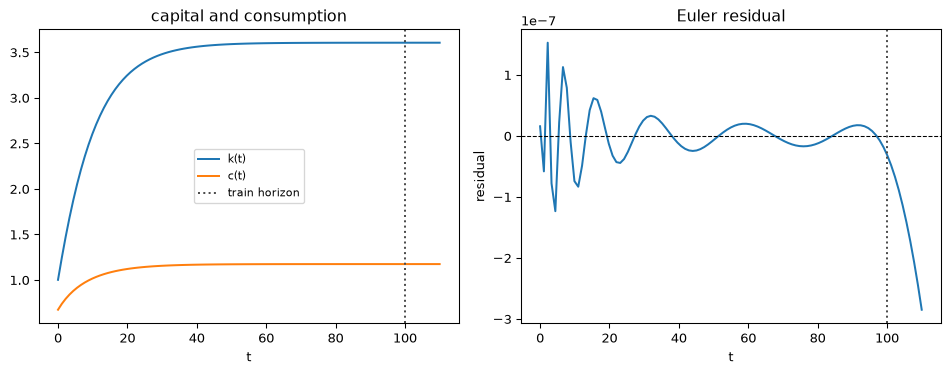

In [8]:
fig, (ax_k, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_k.plot(t_test, k_test, "C0", label="k(t)")
ax_k.plot(t_test, c_test, "C1", label="c(t)")
ax_k.axvline(TRAIN_T, color="0.3", linestyle=":", label="train horizon")
ax_k.set(xlabel="t", title="capital and consumption")
ax_k.legend(fontsize=8)
ax_r.plot(t_test, euler_test, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.axvline(TRAIN_T, color="0.3", linestyle=":")
ax_r.set(xlabel="t", ylabel="residual", title="Euler residual")
fig.tight_layout()
plt.show()